### Instructor Performance and Course Quality Evaluation on EduPro

#### Importing all required libraries

In [136]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools

import warnings
warnings.filterwarnings("ignore")

#### Reading all available datasets

In [2]:
df_courses = pd.read_csv("courses.csv")
df_teachers = pd.read_csv("teachers.csv")
df_transactions = pd.read_csv("transactions.csv")
df_users = pd.read_csv("users.csv")

Let us have a look at the key analytical questions in our dataset

#### Key Analytical Questions

1) What is the overall distribution of instructor ratings?
2) Do instructors with more experience receive higher ratings?
3) Is there a relationship between TeacherRating and CourseRating?
4) Which expertise areas consistently deliver high-quality courses?
5) Are highly rated instructors associated with higher enrollments?

Now, let us have a look at the first question - What is the overall distribution of instructor ratings?

For this, we need to take the teachers dataset into consideration, because that is where we find the ratings of each teacher.

In [3]:
df_teachers.head()

,TeacherID,TeacherName,Age,Gender,Expertise,YearsOfExperience,TeacherRating
0,TC00001,Leonard Montgomery,44,Female,Cybersecurity,6,3.24
1,TC00002,Jill Day,32,Female,Digital Marketing,9,4.14
2,TC00003,Amber Torres,32,Male,Design,4,1.56
3,TC00004,Kristi Scott,34,Female,Machine Learning,9,4.39
4,TC00005,David Williams,34,Male,Finance,2,3.11


Now, we need to check for null values and duplicates for the dataset. Null values need to be dealt with depending on the feature. Duplicates need to be removed.

In [4]:
df_teachers.isna().sum()

TeacherID            0
TeacherName          0
Age                  0
Gender               0
Expertise            0
YearsOfExperience    0
TeacherRating        0
dtype: int64

Now, we see that there are no null values in our dataset. We need to check for rows that contain duplicate data. Some rows can contain different teacher ID but the teacher's name, age and all remain the same. So, we should not consider teacher ID for checking duplicates.

In [5]:
columns_except_teacher_id = df_teachers.columns.difference(["TeacherID"])
df_teachers[columns_except_teacher_id].duplicated().sum()

np.int64(0)

Now, we see that there are no duplicated rows in the dataset. This means that our dataset is clean. We can go ahead with our analysis. Now, we need to check how ratings of teachers are distributed across the dataset.

<Axes: xlabel='TeacherRating', ylabel='Density'>

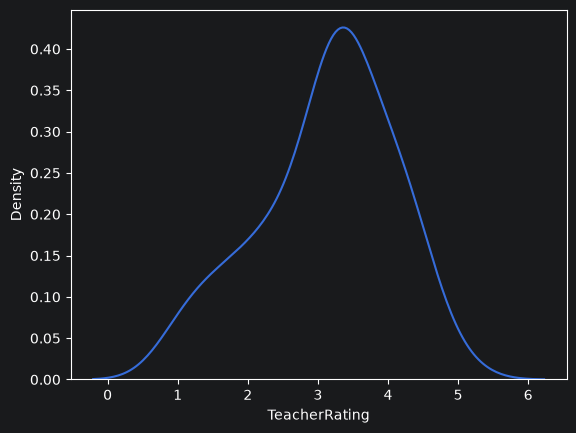

In [6]:
sns.kdeplot(df_teachers["TeacherRating"])

So, we see that ratings of all the instructors on EduPro platform are distributed almost uniformly (with slight variation between ratings 1 and 2). This means that there is a high concentration of teachers around average rating.

Let us also check how the instructors' age and experience are distributed.

<Axes: xlabel='Age', ylabel='Density'>

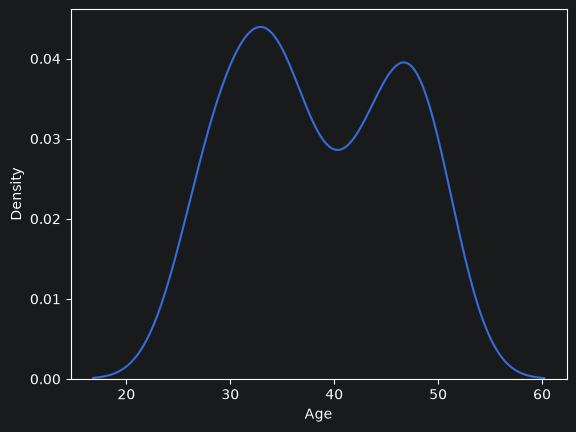

In [7]:
sns.kdeplot(df_teachers["Age"])

From the above graph, we can say that majority of teachers age between 26 and 50.

Now, let us check how well experience is distributed.

<Axes: xlabel='YearsOfExperience', ylabel='Density'>

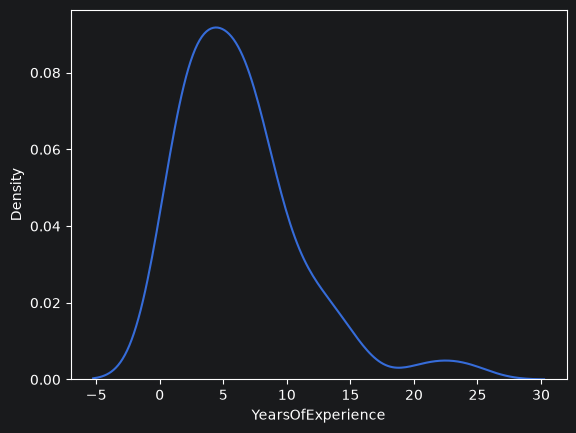

In [8]:
sns.kdeplot(df_teachers["YearsOfExperience"])

The above graph says that there are teachers with experience of less than 0 years - it starts with -5 years of experience, which does not make sense at all. Let us check our dataset again if it contains teachers with negative years of experience.

In [9]:
(df_teachers["YearsOfExperience"] < 0).sum()

np.int64(0)

Now, we see that there are no teachers with 0 years of experience. Let us check why this happened.

In [10]:
print("Number of Teachers with no experience : ",(df_teachers["YearsOfExperience"]==0).sum())
print("Number of Teachers with one year experience : ",(df_teachers["YearsOfExperience"]==1).sum())

Number of Teachers with no experience :  0
Number of Teachers with one year experience :  7


This is because the minimum experience of teachers is 1, and there are 7 teachers with one year of experience. Then until 5 years of experience, the number of teachers increase, and then the number of teachers decrease as their experience increases. This means that teachers with around 5 years of experience dominate our dataset.

Now, let us check how instructors are distributed across expertise

In [52]:
count_values = df_teachers["Expertise"].value_counts()
count_values.values

array([11,  9,  6,  6,  5,  5,  5,  5,  4,  2,  1,  1])

In [ ]:
df_teachers["Expertise"]

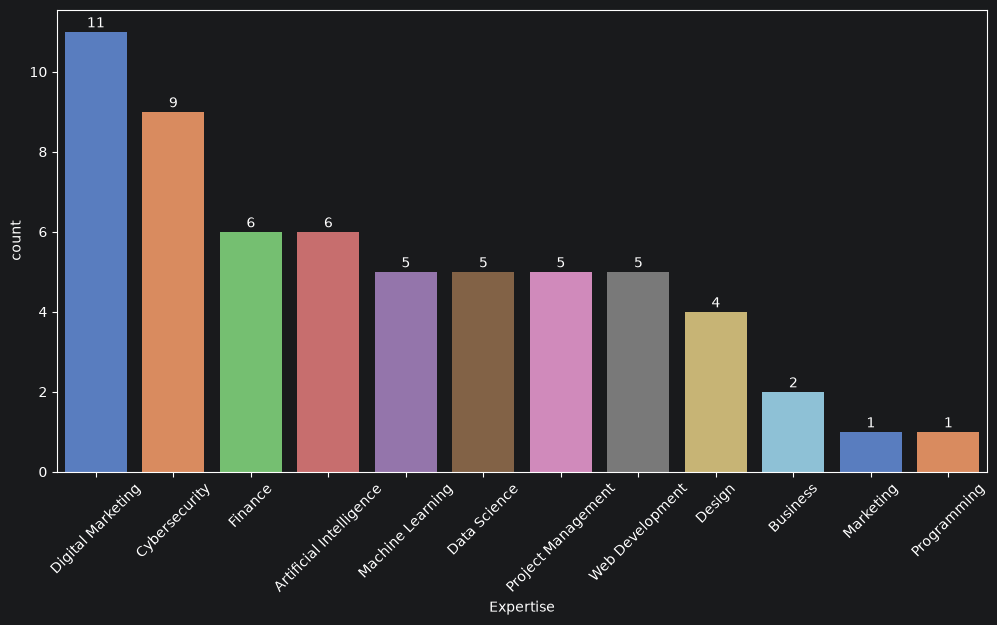

In [137]:
plt.subplots(figsize=(12,6))
count_values = df_teachers["Expertise"].value_counts()
sns.barplot(df_teachers["Expertise"].value_counts(),palette="muted")
plt.xticks(rotation=45)
for i, val in enumerate(count_values.values):
    plt.text(i,val+0.2,str(val),ha="center",va="center")

Now, let us identify who the top performers are and who the bottom ones are. For this, let us see which teachers are rated in the top 90 percentile, and those in the bottom 10 percentile

In [13]:
percentile_90 = df_teachers["TeacherRating"].quantile(0.9)
percentile_10 = df_teachers["TeacherRating"].quantile(0.1)

print("Teachers with highest ratings : ",df_teachers[(df_teachers["TeacherRating"]>percentile_90)]["TeacherName"].values.tolist())
print()
print("Teachers with lowest ratings  : ",df_teachers[(df_teachers["TeacherRating"]<percentile_10)]["TeacherName"].values.tolist())

Teachers with highest ratings :  ['Kristi Scott', 'Angela Beard', 'Debra Escobar', 'Kimberly Miller', 'Yolanda Levine', 'Aaron Kirby']

Teachers with lowest ratings  :  ['Amber Torres', 'Laurie Michael', 'Timothy Bailey', 'Brenda Mclean', 'John Williams', 'Emily Gutierrez']


Our streamlit application can contain options and sliders for various course and teacher related features, and then plot the distributions that we plotted above. So, we need to consider a function in which we consider such options and sliders as formal parameters and return the dedicated plots.

In [14]:
et = pd.merge(left=df_teachers, right=df_transactions, on="TeacherID", how="right")
df = pd.merge(left=df_courses, right=et, on="CourseID", how="right")

In [15]:
def return_plots_0(df_1,variable_to_be_analysed,**kwargs):
    return kwargs
return_plots_0(df,"Amith",CourseName="Amith",CourseCategory="Experience")

{'CourseName': 'Amith', 'CourseCategory': 'Experience'}

In [16]:
def return_plots(df_1,variable_to_be_analysed,**kwargs):
    df = df_1.copy()
    dic = kwargs.copy()
    for i in dic:
        df = df[df[i].isin(dic[i])]
    if variable_to_be_analysed == "TeacherRating":
        ax1 = sns.kdeplot(df["TeacherRating"])
    elif variable_to_be_analysed == "Age":
        ax2 = sns.kdeplot(df["Age"])
    elif variable_to_be_analysed == "YearsOfExperience":
        ax3 = sns.kdeplot(df["YearsOfExperience"])
    elif variable_to_be_analysed == "Expertise":
        fig,ax4 = plt.subplots(figsize=(12,6))
        count_values = df["Expertise"].value_counts()
        ax4 = sns.barplot(df["Expertise"].value_counts(),palette="muted")
        plt.xticks(rotation=45)
        for i, val in enumerate(count_values.values):
            ax4.text(i,val+0.2,str(val),ha="center",va="center")
    plt.show()
    return df

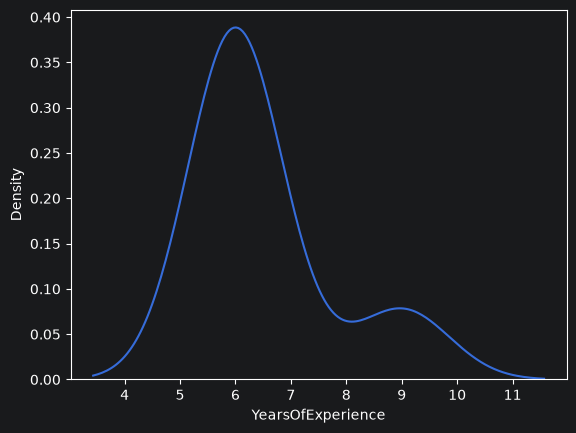

In [17]:
pl = return_plots(df_teachers,"YearsOfExperience",Expertise=["Cybersecurity","Digital Marketing"],YearsOfExperience=[6,9])

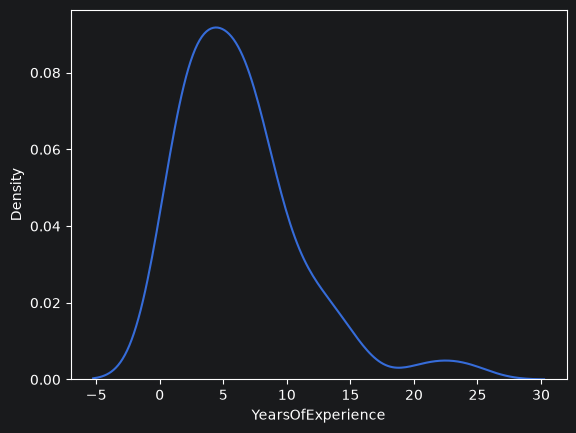

In [18]:
pe = return_plots(df_teachers,"YearsOfExperience")

Now, let us have a look at the second question - Do instructors with more experience receive higher ratings?

For this, we need to consider two variables - Years of Experience and Teacher Rating. We need to plot a graph between the variables.

In [19]:
df[["YearsOfExperience","TeacherRating"]]

,YearsOfExperience,TeacherRating
0,24,4.58
1,24,4.58
2,24,4.58
3,24,4.58
4,21,4.97
...,...,...
9995,24,4.58
9996,24,4.58
9997,24,4.58
9998,24,4.58


<Axes: xlabel='YearsOfExperience', ylabel='TeacherRating'>

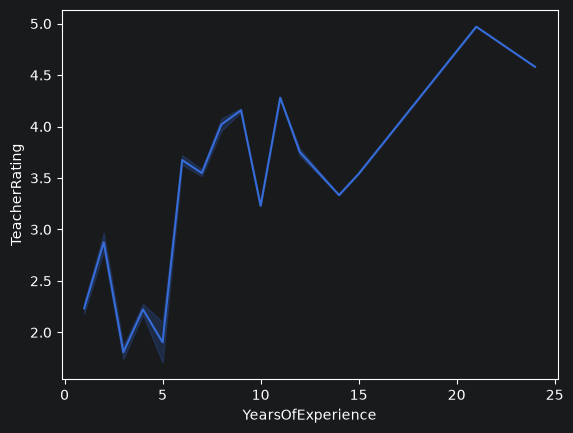

In [20]:
sns.lineplot(x=df["YearsOfExperience"],y=df["TeacherRating"])

<Axes: xlabel='YearsOfExperience', ylabel='TeacherRating'>

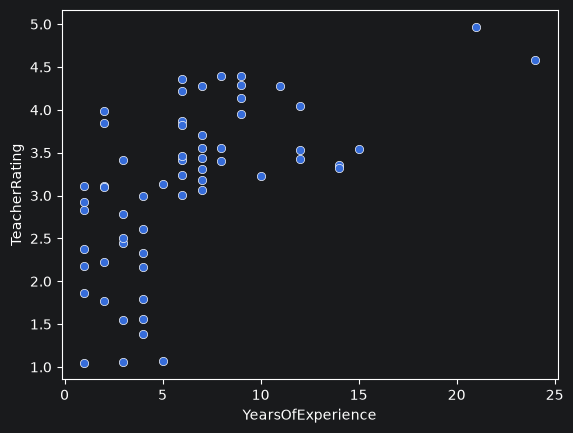

In [21]:
sns.scatterplot(x=df_teachers["YearsOfExperience"],y=df_teachers["TeacherRating"])

From the line plot, we do observe an increasing pattern in teachers' rating with respective to the experience they have, but such increase does not happen at all times. In the scatter plot, we observe teachers from 0 to 5 years of experience holding ratings at all levels - low to high. Let us find the correlation between both the variables.

In [22]:
df_teachers[["YearsOfExperience","TeacherRating"]].corr()["YearsOfExperience"].loc["TeacherRating"]

np.float64(0.5980353982941563)

We observe the correlation coefficient is around 0.598, which means that there is hardly any relation between teacher's experience and rating. However, from the scatter plot, we observe that teachers with 0 to 5 years of experience hold ratings throughout the range, but the highly experienced ones are rated significantly high.

From this, we can infer that low experience does not lead to lower ratings, but experienced ones always get higher ratings. So, the answer to the question is Yes - instructors with more experience do receive higher ratings.

Now, let us have a look at the third question - Is there a relationship between TeacherRating and CourseRating?

Teacher Rating is from Teachers dataset, and Course Rating is from Courses dataset.

We already had a look at the Teachers dataset.

Now, let us have a look at the Courses dataset.

In [23]:
df_courses.head()

,CourseID,CourseName,CourseCategory,CourseType,CourseLevel,CoursePrice,CourseDuration,CourseRating
0,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.00,4.74
1,CR00002,Java Programming,Programming,Free,Intermediate,0.00,37.70,2.43
2,CR00003,C++ for Beginners,Programming,Free,Beginner,0.00,19.53,3.85
3,CR00004,Advanced Python,Programming,Free,Beginner,0.00,45.13,2.88
4,CR00005,Full Stack Development,Programming,Free,Beginner,0.00,28.68,1.28


In [24]:
print("Columns in Teachers dataset : ",df_teachers.columns)
print()
print("Columns in Courses dataset  : ",df_courses.columns)

Columns in Teachers dataset :  Index(['TeacherID', 'TeacherName', 'Age', 'Gender', 'Expertise',
       'YearsOfExperience', 'TeacherRating'],
      dtype='str')

Columns in Courses dataset  :  Index(['CourseID', 'CourseName', 'CourseCategory', 'CourseType', 'CourseLevel',
       'CoursePrice', 'CourseDuration', 'CourseRating'],
      dtype='str')


The above two datasets do not have a common column at all. So, we need to have a look at a third dataset that can combine these two datasets. The third dataset should have a common column with Teachers dataset, and a common one with Courses dataset. Let us have a look at the Transactions dataset.

In [25]:
df_transactions.head()

,TransactionID,UserID,CourseID,TransactionDate,Amount,PaymentMethod,TeacherID
0,TT00001,U00003,CR00016,25/10/2025,0.0,PayPal,TC00040
1,TT00002,U00003,CR00037,13/1/2025,0.0,PayPal,TC00040
2,TT00003,U00003,CR00019,28/3/2025,0.0,Bank Transfer,TC00040
3,TT00004,U00004,CR00048,2/6/2025,0.0,Bank Transfer,TC00040
4,TT00005,U00004,CR00060,10/8/2025,0.0,PayPal,TC00042


In [26]:
print("Columns in Teachers dataset : ",df_teachers.columns)
print()
print("Columns in Courses dataset  : ",df_courses.columns)
print()
print("Columns in Transactions dataset  : ",df_transactions.columns)

Columns in Teachers dataset :  Index(['TeacherID', 'TeacherName', 'Age', 'Gender', 'Expertise',
       'YearsOfExperience', 'TeacherRating'],
      dtype='str')

Columns in Courses dataset  :  Index(['CourseID', 'CourseName', 'CourseCategory', 'CourseType', 'CourseLevel',
       'CoursePrice', 'CourseDuration', 'CourseRating'],
      dtype='str')

Columns in Transactions dataset  :  Index(['TransactionID', 'UserID', 'CourseID', 'TransactionDate', 'Amount',
       'PaymentMethod', 'TeacherID'],
      dtype='str')


We can notice that there is one column in the Transactions dataset that is in common with Teachers dataset (TeacherID), and one column that is common with the Courses dataset (CourseID). So let us now combine these three datasets into one.

In [27]:
et = pd.merge(left=df_teachers, right=df_transactions, on="TeacherID", how="right")
df = pd.merge(left=df_courses, right=et, on="CourseID", how="right")
df.sort_values(by="CourseID",inplace=True,ignore_index=True)

In [28]:
df.head()

,CourseID,CourseName,CourseCategory,CourseType,CourseLevel,CoursePrice,CourseDuration,CourseRating,TeacherID,TeacherName,Age,Gender,Expertise,YearsOfExperience,TeacherRating,TransactionID,UserID,TransactionDate,Amount,PaymentMethod
0,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.0,4.74,TC00042,Yolanda Levine,49,Female,Machine Learning,21,4.97,TT00021,U00018,24/3/2025,472.28,PayPal
1,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.0,4.74,TC00040,Kimberly Miller,49,Male,Cybersecurity,24,4.58,TT00061,U00117,28/11/2025,472.28,PayPal
2,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.0,4.74,TC00042,Yolanda Levine,49,Female,Machine Learning,21,4.97,TT00085,U00147,14/11/2025,472.28,Credit Card
3,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.0,4.74,TC00042,Yolanda Levine,49,Female,Machine Learning,21,4.97,TT00090,U00152,5/11/2025,472.28,Credit Card
4,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.0,4.74,TC00040,Kimberly Miller,49,Male,Cybersecurity,24,4.58,TT00144,U00238,24/8/2025,472.28,PayPal


Now, since we combined three datasets, let us get into our problem - "Is there a relationship between TeacherRating and CourseRating?"

For this, we need to construct a scatter plot, and calculate the correlation coefficient between two features

<Axes: xlabel='TeacherRating', ylabel='CourseRating'>

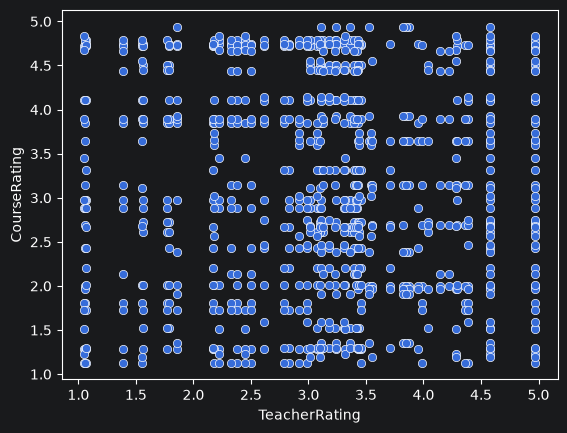

In [29]:
puf = df[["TeacherRating","CourseRating"]].drop_duplicates()

sns.scatterplot(x=puf["TeacherRating"],y=puf["CourseRating"])

In [30]:
puf.drop_duplicates().corr()["TeacherRating"].loc["CourseRating"]

np.float64(-0.03347950418044099)

The scatter plot displays all the points taking over the entire graph, which means that a course of any quality, it can be taught by teacher holding any rating.

For example, if a course has a rating of 1.0, it can be taught by a teacher of any rating. Similarly, if a course is of rating 2.0, it can be taught be a teacher of any rating.

In other words, we can say that course rating is no way related to teacher rating.

To support our argument, we also found out that the correlation of teacher rating with course rating is close to zero.

So, for the question - "Is there a relationship between TeacherRating and CourseRating?", the answer would be No.

Let us find out how correlated the teacher experience is with respect to course rating

<Axes: xlabel='YearsOfExperience', ylabel='CourseRating'>

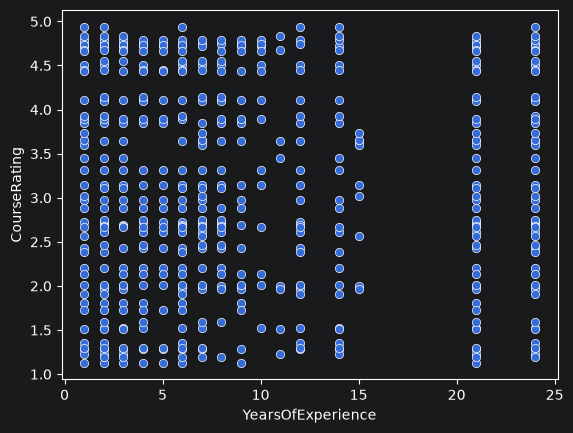

In [31]:
guf = df[["YearsOfExperience","CourseRating"]].drop_duplicates()

sns.scatterplot(x=guf["YearsOfExperience"],y=guf["CourseRating"])

In [32]:
guf.drop_duplicates().corr()["YearsOfExperience"].loc["CourseRating"]

np.float64(0.006123910319907878)

We observe the same pattern between years of experience held by teachers and course rating as we observed with teacher rating vs course rating - points taking over the entire dataset. This means that a teacher with any experience can hold any rating - There is no guarantee that a high-quality course can be dealt by a highly experienced person. Even our near-zero correlation coefficient supports this.

Let us construct heatmaps among years of experience, course rating and teacher rating

<Axes: >

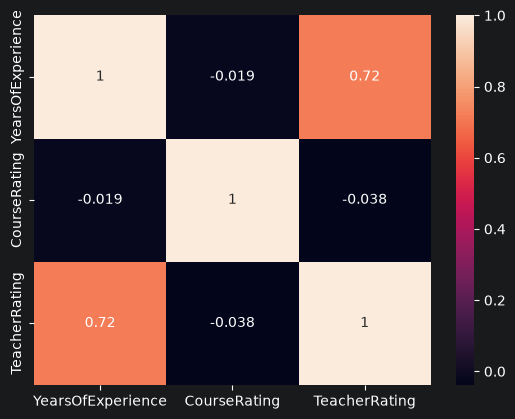

In [33]:
tuf = df[["YearsOfExperience","CourseRating","TeacherRating"]].drop_duplicates()

sns.heatmap(tuf.corr(),annot=True)

Now, let us evaluate the quality of courses by category and level

**Evaluating quality of courses by category**

In [180]:
category_vs_rating = df[["CourseCategory","CourseRating"]]
category_vs_rating["Number"] = 0
for i in category_vs_rating["CourseCategory"].unique():
    pu = category_vs_rating[category_vs_rating["CourseCategory"] == i]
    ctr = 0
    for j in pu.index:
        category_vs_rating.loc[j,"Number"] = ctr
        ctr += 1

<Axes: xlabel='Number', ylabel='CourseRating'>

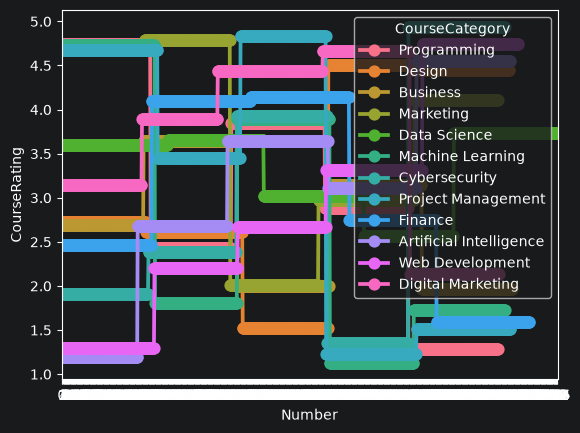

In [184]:

pu = category_vs_rating.copy()

sns.pointplot(x=pu["Number"],y=pu["CourseRating"],hue=pu["CourseCategory"])

In [36]:
each_category = pd.DataFrame(columns=["CourseCategory","LeastRating","HighestRating","AverageRating"])
each_category["CourseCategory"] = category_vs_rating["CourseCategory"].unique()
least_ratings = []
highest_ratings = []
avg_ratings = []
ctr = 0
for i in category_vs_rating["CourseCategory"].unique():
    least_rating = category_vs_rating[category_vs_rating["CourseCategory"] == i]["CourseRating"].min()
    highest_rating = category_vs_rating[category_vs_rating["CourseCategory"] == i]["CourseRating"].max()
    avg_rating = category_vs_rating[category_vs_rating["CourseCategory"] == i]["CourseRating"].mean()

    least_ratings.append(least_rating)
    highest_ratings.append(highest_rating)
    avg_ratings.append(avg_rating)

each_category["LeastRating"] = least_ratings
each_category["HighestRating"] = highest_ratings
each_category["AverageRating"] = avg_ratings

In [226]:
def return_category_vs_rating(df_1,display_graph=False,**kwargs):
    df = df_1.copy()
    dic = kwargs.copy()
    for i in dic:
        df = df[df[i].isin(dic[i])]

    category_vs_rating = df[["CourseCategory","CourseRating"]]
    category_vs_rating["Number"] = 0
    for i in category_vs_rating["CourseCategory"].unique():
        pu = category_vs_rating[category_vs_rating["CourseCategory"] == i]
        ctr = 0
        for j in pu.index:
            category_vs_rating.loc[j,"Number"] = ctr
            ctr += 1

    each_category = pd.DataFrame(columns=["CourseCategory","LeastRating","HighestRating","AverageRating"])
    each_category["CourseCategory"] = category_vs_rating["CourseCategory"].unique()

    least_ratings = []
    highest_ratings = []
    avg_ratings = []
    ctr = 0
    for i in category_vs_rating["CourseCategory"].unique():
        least_rating = category_vs_rating[category_vs_rating["CourseCategory"] == i]["CourseRating"].min()
        highest_rating = category_vs_rating[category_vs_rating["CourseCategory"] == i]["CourseRating"].max()
        avg_rating = category_vs_rating[category_vs_rating["CourseCategory"] == i]["CourseRating"].mean()

        least_ratings.append(least_rating)
        highest_ratings.append(highest_rating)
        avg_ratings.append(avg_rating)

    each_category["LeastRating"] = least_ratings
    each_category["HighestRating"] = highest_ratings
    each_category["AverageRating"] = avg_ratings
    if display_graph == True:
        sns.lineplot(x=category_vs_rating["Number"],y=category_vs_rating["CourseRating"],hue=category_vs_rating["CourseCategory"],drawstyle="steps-post",lw=4)
        plt.xticks([])
        plt.xlabel(None)
        plt.show()

    return category_vs_rating, each_category, df

In [227]:
cvr, ec, dd = return_category_vs_rating(df,CourseCategory=['Programming','Design','Business'])

**Evaluating quality of courses by level**

In [228]:
level_vs_rating = df[["CourseLevel","CourseRating"]]
tu = []
level_vs_rating["Number"] = 0
for i in level_vs_rating["CourseLevel"].unique():
    pu = level_vs_rating[level_vs_rating["CourseLevel"] == i]
    ctr = 0
    for j in pu.index:
        level_vs_rating.loc[j,"Number"] = ctr
        ctr += 1

In [229]:
each_level = pd.DataFrame(columns=["CourseLevel","LeastRating","HighestRating","AverageRating"])
each_level["CourseLevel"] = df["CourseLevel"].unique()
least_ratings = []
highest_ratings = []
avg_ratings = []
ctr = 0
for i in df["CourseLevel"].unique():
    least_rating = df[df["CourseLevel"] == i]["CourseRating"].min()
    highest_rating = df[df["CourseLevel"] == i]["CourseRating"].max()
    avg_rating = df[df["CourseLevel"] == i]["CourseRating"].mean()

    least_ratings.append(least_rating)
    highest_ratings.append(highest_rating)
    avg_ratings.append(avg_rating)

each_level["LeastRating"] = least_ratings
each_level["HighestRating"] = highest_ratings
each_level["AverageRating"] = avg_ratings

In [230]:
def return_level_vs_rating(df_1,display_graph=False,**kwargs):
    df = df_1.copy()
    dic = kwargs.copy()
    for i in dic:
        df = df[df[i].isin(dic[i])]

    level_vs_rating = df[["CourseLevel","CourseRating"]]
    level_vs_rating["Number"] = 0
    for i in level_vs_rating["CourseLevel"].unique():
        pu = level_vs_rating[level_vs_rating["CourseLevel"] == i]
        ctr = 0
        for j in pu.index:
            level_vs_rating.loc[j,"Number"] = ctr
            ctr += 1

    each_level = pd.DataFrame(columns=["CourseLevel","LeastRating","HighestRating","AverageRating"])
    each_level["CourseLevel"] = df["CourseLevel"].unique()
    least_ratings = []
    highest_ratings = []
    avg_ratings = []
    ctr = 0
    for i in df["CourseLevel"].unique():
        least_rating = df[df["CourseLevel"] == i]["CourseRating"].min()
        highest_rating = df[df["CourseLevel"] == i]["CourseRating"].max()
        avg_rating = df[df["CourseLevel"] == i]["CourseRating"].mean()

        least_ratings.append(least_rating)
        highest_ratings.append(highest_rating)
        avg_ratings.append(avg_rating)

    each_level["LeastRating"] = least_ratings
    each_level["HighestRating"] = highest_ratings
    each_level["AverageRating"] = avg_ratings

    if display_graph == True:
        sns.lineplot(x=level_vs_rating["Number"],y=level_vs_rating["CourseRating"],hue=level_vs_rating["CourseLevel"],drawstyle="steps-post",lw=4)
        plt.xticks([])
        plt.xlabel(None)
        plt.show()

    return level_vs_rating, each_level, df

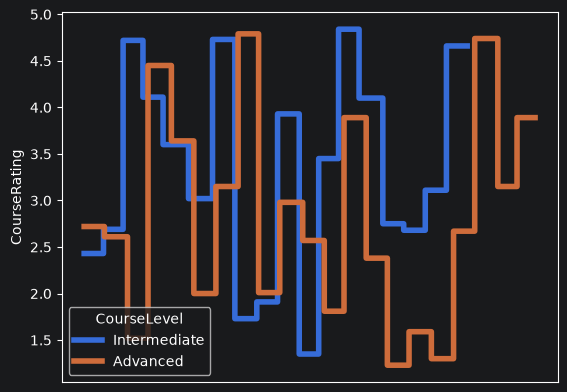

In [231]:
lvr, el, ll = return_level_vs_rating(df,display_graph=True,CourseLevel=["Intermediate","Advanced"])

**Comparing Gender and Course level**

In [232]:
gender_vs_level = df[["Gender","CourseLevel"]].value_counts().reset_index().sort_values(by=["Gender"])

gender_vs_level["Order-1"] = list(map(lambda x: 0 if x == "Female" else 1,gender_vs_level["Gender"]))
gender_vs_level["Order-2"] = list(map(lambda x: 0 if x == "Beginner" else (1 if x == "Intermediate" else 2),gender_vs_level["CourseLevel"]))
gender_vs_level.sort_values(by=["Order-1","Order-2"],inplace=True,ignore_index=True)
gender_vs_level = gender_vs_level.drop(columns=["Order-1","Order-2"])
gender_vs_level

,Gender,CourseLevel,count
0,Female,Beginner,1724
1,Female,Intermediate,1414
2,Female,Advanced,1788
3,Male,Beginner,1849
4,Male,Intermediate,1538
5,Male,Advanced,1687


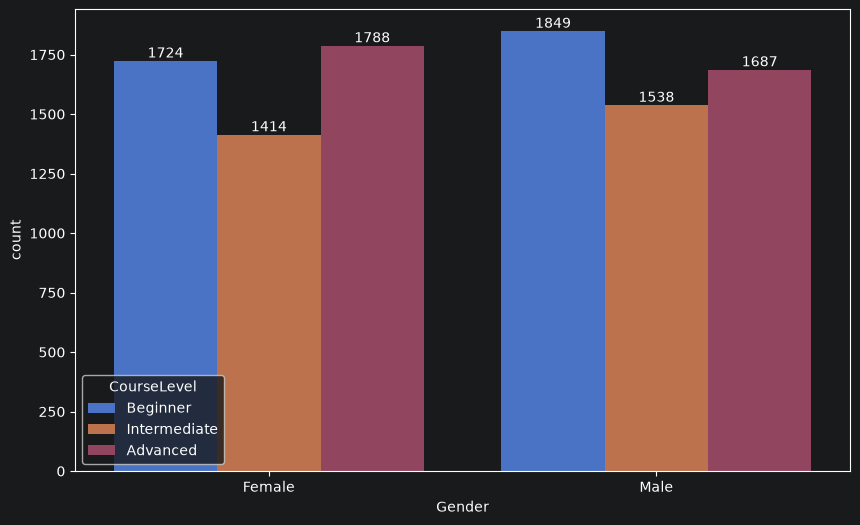

In [233]:
plt.figure(figsize=(10,6))
ax = sns.barplot(x=gender_vs_level["Gender"],y=gender_vs_level["count"],hue=gender_vs_level["CourseLevel"])
sns.move_legend(ax,loc="lower left")
for i in ax.containers:
    ax.bar_label(container=i)

From the above graph, we can say that there is small significance of differences in both males and females attending courses at three levels. Most of the females attend advanced courses, while most males attend beginner courses. Males dominate females at beginner and intermediate levels, while it is the other way around at advanced level.

**Identification of categories with consistently high or low ratings**

In [234]:
list_of_course_categories

<ArrowStringArray>
[            'Programming',                  'Design',
                'Business',               'Marketing',
            'Data Science',        'Machine Learning',
           'Cybersecurity',      'Project Management',
                 'Finance', 'Artificial Intelligence',
         'Web Development',       'Digital Marketing']
Length: 12, dtype: str

In [235]:
df[df["CourseCategory"]=="Programming"]

,CourseID,CourseName,CourseCategory,CourseType,CourseLevel,CoursePrice,CourseDuration,CourseRating,TeacherID,TeacherName,Age,Gender,Expertise,YearsOfExperience,TeacherRating,TransactionID,UserID,TransactionDate,Amount,PaymentMethod
0,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.00,4.74,TC00042,Yolanda Levine,49,Female,Machine Learning,21,4.97,TT00021,U00018,24/3/2025,472.28,PayPal
1,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.00,4.74,TC00040,Kimberly Miller,49,Male,Cybersecurity,24,4.58,TT00061,U00117,28/11/2025,472.28,PayPal
2,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.00,4.74,TC00042,Yolanda Levine,49,Female,Machine Learning,21,4.97,TT00085,U00147,14/11/2025,472.28,Credit Card
3,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.00,4.74,TC00042,Yolanda Levine,49,Female,Machine Learning,21,4.97,TT00090,U00152,5/11/2025,472.28,Credit Card
4,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.00,4.74,TC00040,Kimberly Miller,49,Male,Cybersecurity,24,4.58,TT00144,U00238,24/8/2025,472.28,PayPal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
801,CR00005,Full Stack Development,Programming,Free,Beginner,0.00,28.68,1.28,TC00042,Yolanda Levine,49,Female,Machine Learning,21,4.97,TT09436,U01290,6/8/2025,0.00,Credit Card
802,CR00005,Full Stack Development,Programming,Free,Beginner,0.00,28.68,1.28,TC00042,Yolanda Levine,49,Female,Machine Learning,21,4.97,TT09653,U00071,28/3/2025,0.00,Bank Transfer
803,CR00005,Full Stack Development,Programming,Free,Beginner,0.00,28.68,1.28,TC00040,Kimberly Miller,49,Male,Cybersecurity,24,4.58,TT09864,U01746,19/3/2025,0.00,PayPal
804,CR00005,Full Stack Development,Programming,Free,Beginner,0.00,28.68,1.28,TC00042,Yolanda Levine,49,Female,Machine Learning,21,4.97,TT09978,U02825,9/6/2025,0.00,PayPal


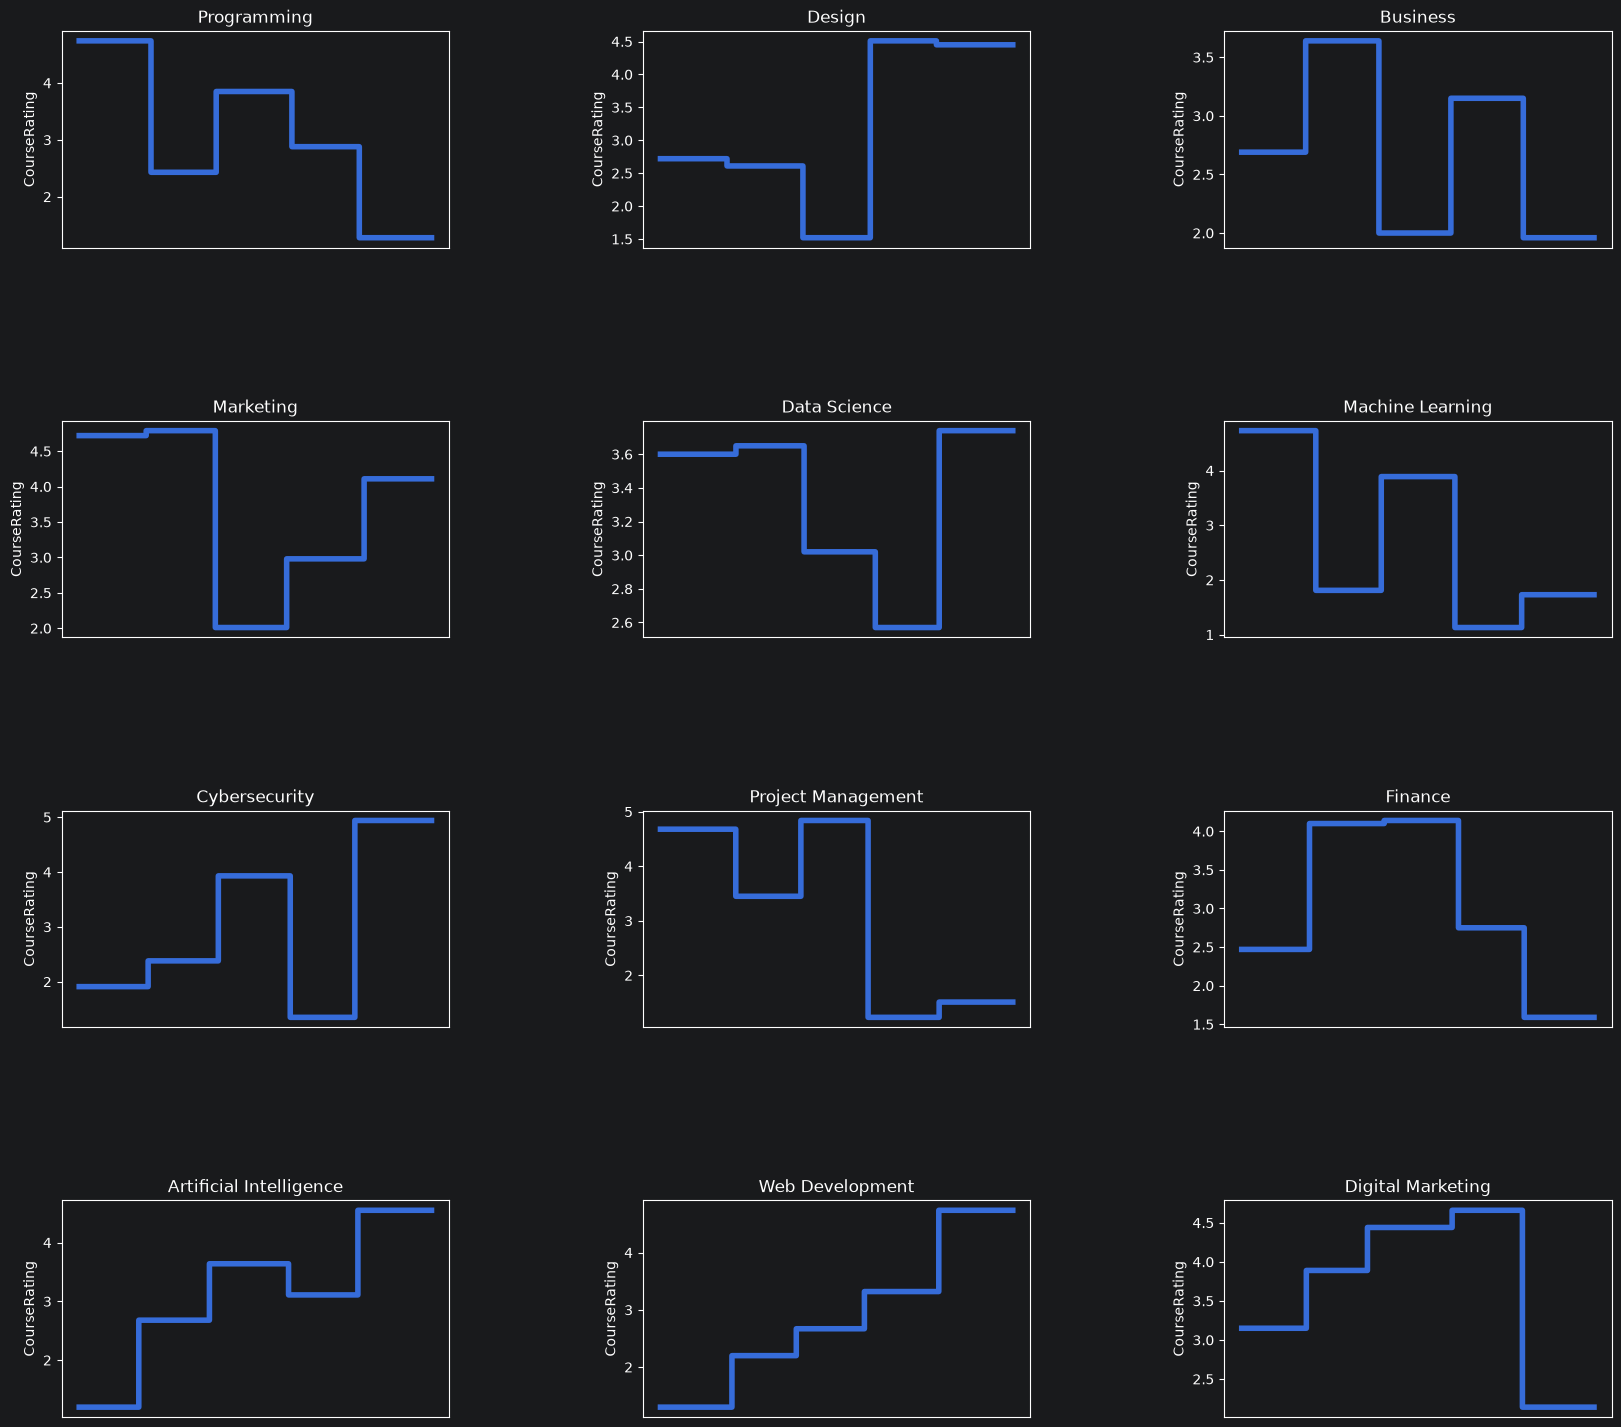

In [241]:
nrows = 4
ncols = len(df["CourseCategory"].unique())//nrows

list_of_course_categories = df["CourseCategory"].unique()

# fig, ax = plt.subplots(nrows=len(list_of_course_categories),ncols=1,figsize=(20,10))
fig, ax = plt.subplots(nrows=nrows,ncols=ncols,figsize=(20,18))
fig.subplots_adjust(hspace=0.8, wspace=0.5)

ctr = 0
for (i,j) in list(itertools.product(range(nrows),range(ncols))):
    course_category = list_of_course_categories[ctr]
    lf = df[df["CourseCategory"]==course_category]["CourseRating"].reset_index(drop=True)
    sns.lineplot(lf,ax=ax[i,j],drawstyle="steps-post",lw=4)
    ax[i,j].set_title(course_category)
    ax[i,j].set_xticks([])

    #ax[ctr] = sns.pointplot(lf)
    #
    ctr += 1

As we have a look at the above graphs, none of the categories show a consistently high or low rating. Every one swings widely, from roughly 1.2-1.5 at the low end to 4.5-5 at the high end, with Data Science the only partial exception (it stays in a narrower 2.6-3.7 band, so it is consistently mid-range).